# Análise de dados de hipotireoidismo
Trabalho de Ciência de Dados

## 1. Leitura e limpeza
Retirei as linhas repetidas para não contar o mesmo registro duas vezes. Também marquei a idade de 455 anos como ausente, pois não havia como saber a idade correta. Mantive os nomes P e N: o CSV não explica o significado clínico desses códigos.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, recall_score, precision_score, ConfusionMatrixDisplay

arquivo = Path("Base_M43_Pratique_Hypothyroid(10).csv")
if not arquivo.exists():
    arquivo = Path("Base_M43_Pratique_Hypothyroid.csv")
dados = pd.read_csv(arquivo, na_values="?")
print("Original:", dados.shape, "| duplicatas:", dados.duplicated().sum())
dados = dados.drop_duplicates().copy()
numericas = ["age", "TSH", "T3", "TT4", "T4U", "FTI"]
for coluna in numericas:
    dados[coluna] = pd.to_numeric(dados[coluna], errors="coerce")
# Uma idade de 455 anos é inválida; trato como ausente.
dados.loc[(dados["age"] < 0) | (dados["age"] > 120), "age"] = float("nan")
print("Após limpeza:", dados.shape)
print(dados["binaryClass"].value_counts())
print("Ausentes nas variáveis usadas:")
print(dados[numericas + ["sex"]].isna().sum())

Original: (3772, 30) | duplicatas: 61
Após limpeza: (3711, 30)
binaryClass
P    3420
N     291
Name: count, dtype: int64
Ausentes nas variáveis usadas:
age      2
TSH    309
T3     709
TT4    171
T4U    327
FTI    325
sex    149
dtype: int64


## 2. Classes e TSH
P tem muito mais registros que N. Por isso comparei o modelo com um classificador que prevê apenas P: ele pode acertar muitos registros e ainda deixar todos os N de fora.

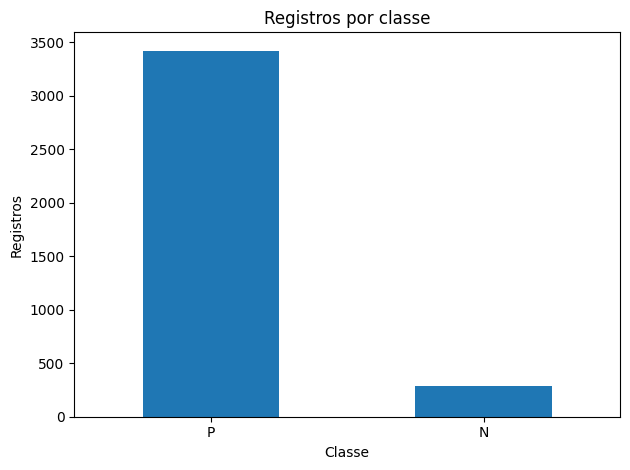

In [2]:
contagem = dados["binaryClass"].value_counts().reindex(["P", "N"])
ax = contagem.plot(kind="bar", rot=0, title="Registros por classe")
ax.set(xlabel="Classe", ylabel="Registros")
plt.tight_layout()
plt.show()

No gráfico de TSH, usei o limite de 50 no eixo vertical para enxergar melhor a diferença entre as classes. Os valores maiores continuam nos dados usados no treino.

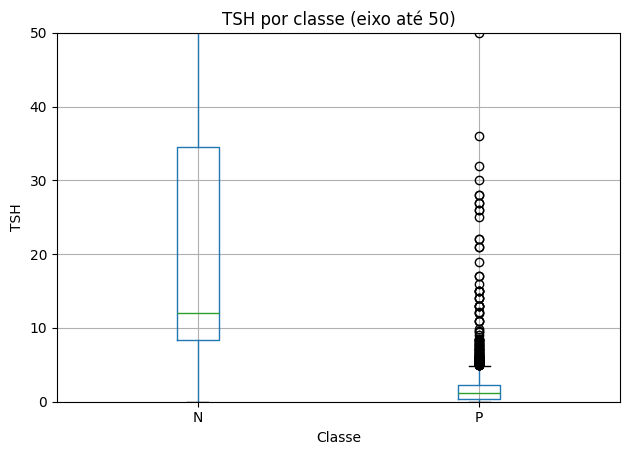

In [3]:
ax = dados.boxplot(column="TSH", by="binaryClass")
plt.ylim(0, 50)
plt.suptitle("")
plt.title("TSH por classe (eixo até 50)")
plt.xlabel("Classe")
plt.ylabel("TSH")
plt.tight_layout()
plt.show()

## 3. Treino e comparação
Separei 25% dos registros para teste, mantendo a proporção das classes. Comparei o Dummy, que prevê sempre P, com a regressão logística.

Preenchi os exames ausentes com a mediana do treino, pois alguns valores de TSH são muito altos. Usei o `Pipeline` para fazer esse preparo sem usar os dados de teste. Também padronizei as variáveis numéricas, codifiquei sexo e apliquei `class_weight="balanced"`, já que N é minoria.

In [4]:
X = dados[numericas + ["sex"]]
y = dados["binaryClass"]
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_treino, y_treino)

preparo = ColumnTransformer([
    ("num", Pipeline([
        ("preencher", SimpleImputer(strategy="median")),
        ("padronizar", StandardScaler())
    ]), numericas),
    ("cat", Pipeline([
        ("preencher", SimpleImputer(strategy="most_frequent")),
        ("codificar", OneHotEncoder(handle_unknown="ignore"))
    ]), ["sex"])
])
modelo = Pipeline([
    ("preparo", preparo),
    ("regressao", LogisticRegression(max_iter=1000, class_weight="balanced"))
])
modelo.fit(X_treino, y_treino)

previsao = modelo.predict(X_teste)
linhas = []
for nome, pred in [("Dummy", dummy.predict(X_teste)), ("Regressão logística", previsao)]:
    linhas.append({
        "Modelo": nome,
        "Acurácia": round(accuracy_score(y_teste, pred), 3),
        "Acurácia balanceada": round(balanced_accuracy_score(y_teste, pred), 3),
        "Recall N": round(recall_score(y_teste, pred, pos_label="N", zero_division=0), 3),
        "Precisão N": round(precision_score(y_teste, pred, pos_label="N", zero_division=0), 3)
    })
resultado = pd.DataFrame(linhas).set_index("Modelo")
print(resultado.to_string())

                     Acurácia  Acurácia balanceada  Recall N  Precisão N
Modelo                                                                  
Dummy                   0.921                0.500     0.000       0.000
Regressão logística     0.967                0.957     0.945       0.719


O Dummy teve mais de 92% de acurácia sem acertar nenhum N. A regressão identificou 69 dos 73 registros N no teste, embora também tenha classificado alguns P como N.

## 4. Matriz de confusão

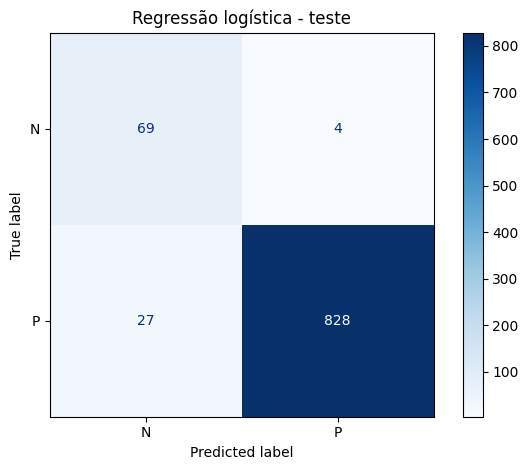

In [5]:
ConfusionMatrixDisplay.from_predictions(
    y_teste, previsao, labels=["N", "P"], cmap="Blues"
)
plt.title("Regressão logística - teste")
plt.tight_layout()
plt.show()

Dos 73 registros N do teste, quatro foram previstos como P. Outros 27 registros P foram previstos como N. Por isso, além da acurácia de 96,7%, observei os erros de cada classe.

## 5. Conferência de erros
Separei as previsões erradas para conferir os valores de TSH e FTI. Os números das linhas são os índices preservados do CSV após retirar duplicatas.

In [6]:
erros = X_teste.loc[previsao != y_teste].copy()
erros["real"] = y_teste.loc[erros.index]
erros["previsto"] = previsao[previsao != y_teste]
print("N previstos como P:")
print(erros.loc[erros["real"] == "N", ["TSH", "FTI", "real", "previsto"]].head(4).to_string())
print("\nP previstos como N (exemplos):")
print(erros.loc[erros["real"] == "P", ["TSH", "FTI", "real", "previsto"]].head(3).to_string())

N previstos como P:
      TSH    FTI real previsto
1888  6.2  121.0    N        P
3500  6.3  119.0    N        P
2466  7.4  117.0    N        P
1181  6.8  111.0    N        P

P previstos como N (exemplos):
       TSH   FTI real previsto
1450   4.7  17.0    P        N
1174  21.0  84.0    P        N
879    6.0  94.0    P        N


Entre os P previstos como N, a linha 1174 tem TSH de 21 e FTI de 84; a linha 1450 tem TSH de 4,7 e FTI de 17. Já os quatro N previstos como P têm TSH entre 6,2 e 7,4 e FTI entre 111 e 121. Esses valores ajudam a comparar os erros, mas não bastam para dizer que algum rótulo está incorreto.

## 6. Conclusão
Após retirar 61 duplicatas, ficaram 3.711 registros (3.420 P e 291 N). O Dummy teve 92,1% de acurácia, mas não identificou nenhum N. Já a regressão logística identificou 69 dos 73 registros N do teste, com quatro N previstos como P e 27 P previstos como N. Sua acurácia foi de 96,7%, com Recall de 94,5% e Precisão de 71,9% para N.

Esses resultados são desta base e desta divisão de teste. Não testei o modelo em outras bases.

**Fontes usadas:** CSV fornecido para o exercício e documentação do scikit-learn para os classificadores e métricas.